# DATA 3401 Honors Project: Quantitative Trading Backtester & ML Market Regime Classifier
**Student:** Jason Pham  
**Course:** DATA 3401 (Python for Data Science 1)  
**Instructor:** Dr. Ce Brian Bian  
**Date:** Fall 2026  

---
## Executive Summary & System Architecture
This honors contract research project develops a unified quantitative finance and machine learning system comprised of two interconnected modules:

1. **Project 1 (Quantitative Trading Backtester):** An object-oriented simulation engine that tests systematic trading strategies against 5 years of daily market data for the SPDR S&P 500 ETF Trust (`SPY`). We evaluate two core technical strategies:
   - **Dual Moving Average Crossover (20-day vs. 50-day SMA)**
   - **RSI Mean Reversion (14-period Relative Strength Index calculated manually using NumPy: Buy < 30, Sell > 70)**
2. **Project 2 (ML Market Regime Classifier):** A binary Logistic Regression classifier built entirely from first principles in NumPy (without external machine learning libraries like `scikit-learn`). The model predicts whether the forward weekly market regime will be **Bullish** ($P_{t+5} > \text{SMA}_{50,t}$) or **Bearish** using 4 engineered technical features:
   - 5-day rolling return (`ret_5d`)
   - 20-day return volatility (`vol_20d`)
   - 14-day RSI (`rsi_14`)
   - Price to 50-day SMA ratio (`sma50_ratio`)
3. **System Integration (The Hybrid Strategy):** We bridge both systems by utilizing the ML classifier's forward regime predictions as an independent trade filter for the Backtester. Trade positions are held only when technical trend conditions are active **and** the ML classifier independently confirms a Bullish market regime.


In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from datetime import datetime, timedelta

# Append project modules
sys.path.append(os.path.abspath('.'))
sys.path.append(os.path.abspath('..'))
sys.path.append(os.path.abspath('../Market_Regime_Prediction'))
sys.path.append(os.path.abspath('Trading Strategies Backtesting System'))
sys.path.append(os.path.abspath('Market_Regime_Prediction'))

from pipeline import DataPipeline
from strategy import Strategy, MACrossover, RSIMeanReversion, MLHybridStrategy
from backtester import Backtest
from preprocessing_pipeline import Pipeline
from LogisticRegression import LogisticRegression

# Visual formatting setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
print("System modules loaded successfully.")


System modules loaded successfully.


## Chapter 1: Data Acquisition & Preprocessing Pipeline
We utilize `DataPipeline` to load and clean 5 years of historical daily market data for the SPDR S&P 500 ETF (`SPY`). The pipeline handles input normalization using `isinstance()`, extracts adjusted closing prices to account for splits and corporate actions, and fills missing exchange bars via forward-filling.


In [2]:
# Initialize DataPipeline and load 5-year historical SPY dataset
data_pipeline = DataPipeline(
    start_date=datetime.now() - timedelta(days=5*365),
    end_date=datetime.now(),
    intervals="1d",
    ticker="SPY"
)

csv_path = "SPY_5_years" if os.path.exists("SPY_5_years") else "Trading Strategies Backtesting System/SPY_5_years"
df_spy = data_pipeline.fetch_data(csv_path)

print(f"Loaded {len(df_spy)} daily bars from: {csv_path}")
print(f"Date Range: {df_spy.index[0].strftime('%Y-%m-%d')} to {df_spy.index[-1].strftime('%Y-%m-%d')}")
display(df_spy.head())


Loaded 1254 daily bars from: SPY_5_years
Date Range: 2021-09-02 to 2026-09-01


Price,Close,High,Low,Open,Volume
Date,,,,,
2021-09-02,423.565338,424.369107,422.369012,423.686845,42501000
2021-09-03,423.462433,423.976497,422.032449,422.434362,47170500
2021-09-07,421.948395,423.210152,421.275459,423.116683,51671500
2021-09-08,421.434265,422.144593,419.518255,421.415583,56181900
2021-09-09,419.630554,422.985875,419.387541,421.238120,57970400


## Chapter 2: Technical Strategies Simulation (Project 1)
We simulate the performance of two foundational quantitative trading strategies across the full 5-year dataset using our object-oriented `Backtest` engine:
1. **Dual MA Crossover (Trend Following):**
   - Entry: Short 20-day SMA crosses above Long 50-day SMA (`signal = 1`).
   - Exit: Short 20-day SMA crosses below Long 50-day SMA (`signal = 0`).
2. **RSI Mean Reversion (Counter-Trend Oscillator):**
   - Entry: 14-period RSI drops below 30 (oversold condition, `signal = 1`).
   - Exit: 14-period RSI rises above 70 (overbought condition, `signal = 0`).


--- Dual MA Crossover (20/50) Performance Metrics ---
Total returns             : 0.1854
Sharpe Ratio              : 0.3623
Max drawdown              : -0.2880
Win rate                  : 0.5000
Profit factor             : 1.6409
Baseline score (buy-hold) : 0.7985


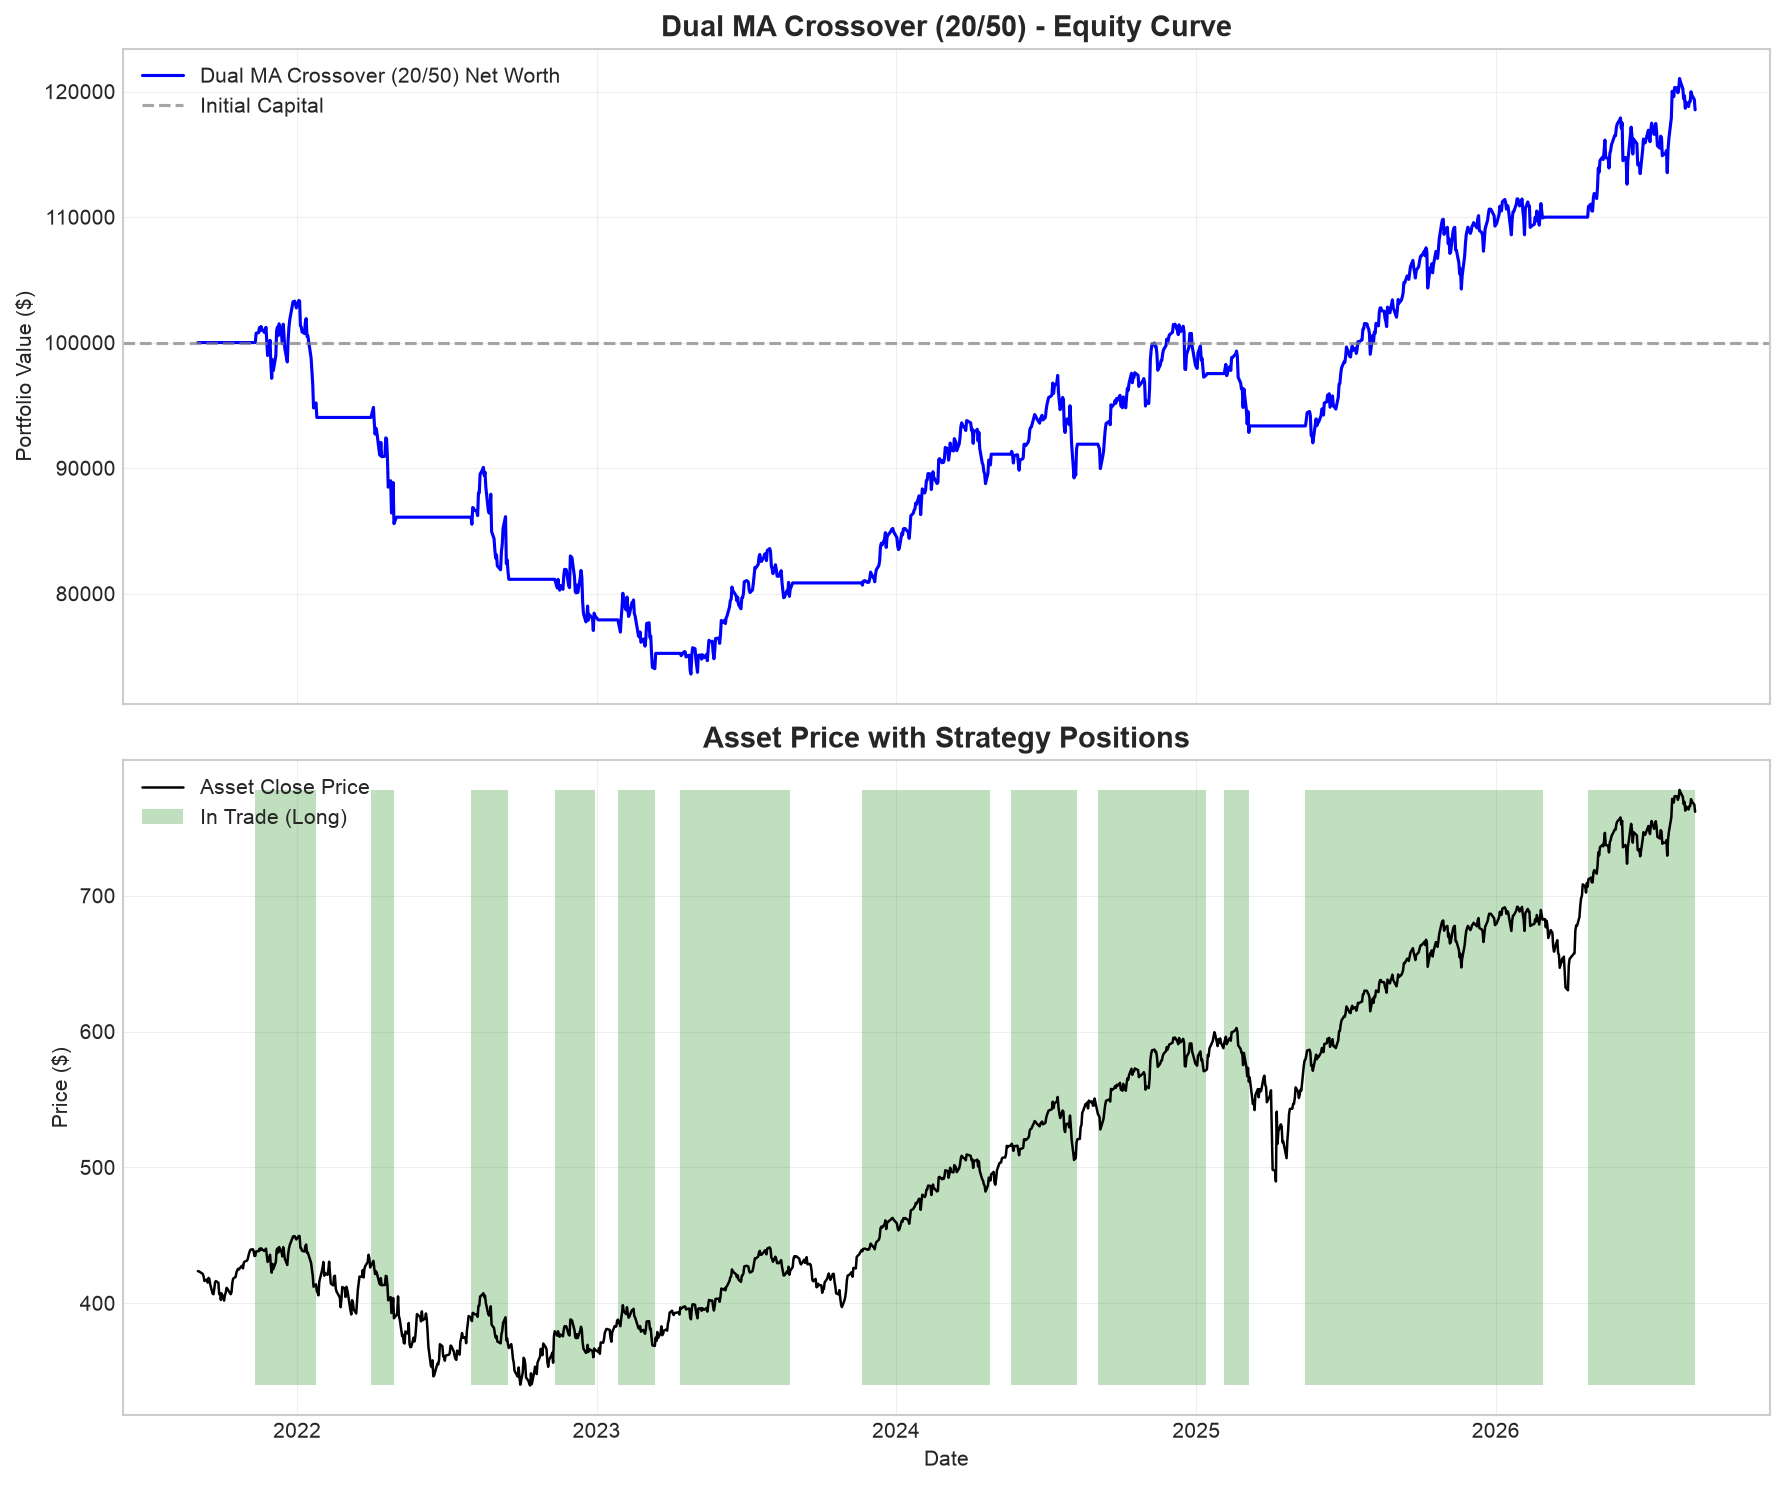

In [3]:
# Backtest Dual Moving Average Crossover (20/50)
ma_data = df_spy.copy()
ma_strategy = MACrossover(ma_data, short_window=20, long_window=50)
backtest_ma = Backtest(ma_data, ma_strategy, starting_cash=100000)
backtest_ma.run()
metrics_ma = backtest_ma.cal_metrics()

print("--- Dual MA Crossover (20/50) Performance Metrics ---")
for k, v in metrics_ma.items():
    print(f"{k:26s}: {v:,.4f}" if isinstance(v, float) else f"{k:26s}: {v}")

backtest_ma.plot_result(strategy_name="Dual MA Crossover (20/50)")


--- RSI Mean Reversion Performance Metrics ---
Total returns             : 0.3248
Sharpe Ratio              : 0.4903
Max drawdown              : -0.1885
Win rate                  : 0.7692
Profit factor             : 3.0821
Baseline score (buy-hold) : 0.7985


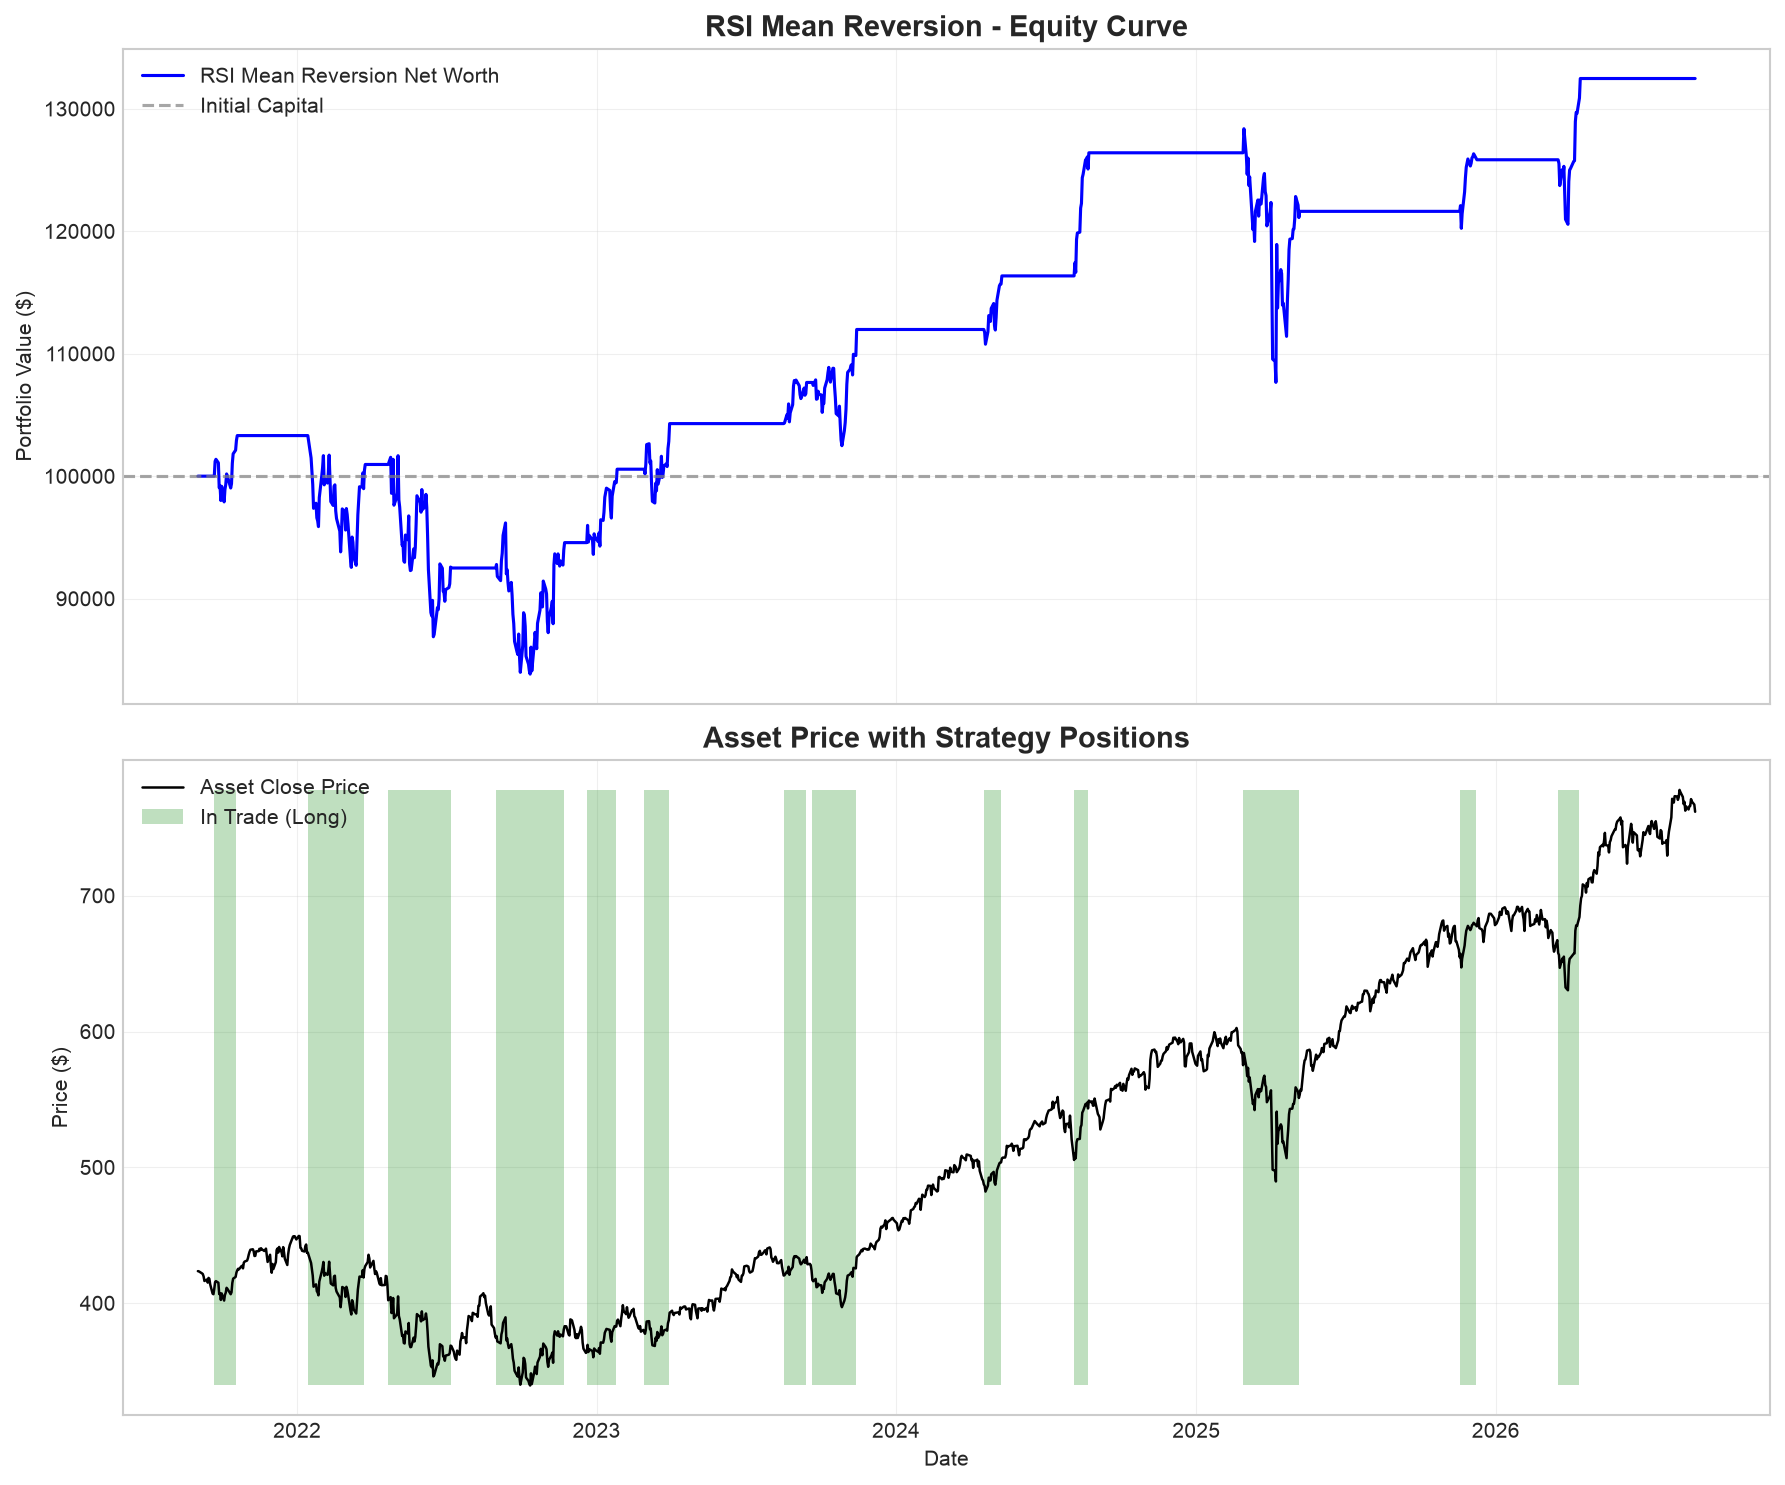

In [4]:
# Backtest RSI Mean Reversion Strategy
rsi_data = df_spy.copy()
rsi_strategy = RSIMeanReversion(rsi_data, time_window=14)
backtest_rsi = Backtest(rsi_data, rsi_strategy, starting_cash=100000)
backtest_rsi.run()
metrics_rsi = backtest_rsi.cal_metrics()

print("--- RSI Mean Reversion Performance Metrics ---")
for k, v in metrics_rsi.items():
    print(f"{k:26s}: {v:,.4f}" if isinstance(v, float) else f"{k:26s}: {v}")

backtest_rsi.plot_result(strategy_name="RSI Mean Reversion")


## Chapter 3: Project 2 - Feature Engineering & NumPy Logistic Regression
We now construct the machine learning market regime classifier:
1. **Feature Engineering Pipeline (`Pipeline`)**:
   - Calculates 5-day rolling return, 20-day volatility, 14-day RSI, and Price/SMA50 ratio.
   - Generates forward 5-day market regime target: $y=1$ (Bullish Regime) if $P_{t+5} > \text{SMA}_{50,t}$, else $0$ (Bearish Regime). Defining the target relative to the 50-day trend regime prevents short-term 5-day return mean-reversion noise from inverting the learned weights.
   - Drops boundary `NaN`s (first 49 rows from 50-day SMA warmup, last 5 rows from forward shifting).
   - Chronological 80/20 train/test split.
   - Zero-leakage Z-score standardization ($Z = \frac{X - \mu_{\text{train}}}{\sigma_{\text{train}}}$) fit on training data only.
2. **First-Principles Logistic Regression (`LogisticRegression`)**:
   - Implemented entirely in NumPy without external ML libraries.
   - Balanced class weighting prevents majority-class drift in upward-trending markets.
   - Sigmoid activation with numerical bounds clipping and convex optimization via Binary Cross-Entropy loss.


In [5]:
# Execute Feature Engineering and Zero-Leakage Splitting/Scaling
ml_pipe = Pipeline(df_spy)
ml_pipe.generate_features()
ml_pipe.generate_target(horizon=5)
X_train, X_test, y_train, y_test = ml_pipe.train_test_split_scale(train_ratio=0.8)
test_df = ml_pipe.get_test_dataframe()

print(f"Cleaned Total Samples: {len(ml_pipe.clean_df)}")
print(f"Training Set Samples:  {X_train.shape[0]} ({len(ml_pipe.train_df)/len(ml_pipe.clean_df):.1%})")
print(f"Testing Set Samples:   {X_test.shape[0]} ({len(ml_pipe.test_df)/len(ml_pipe.clean_df):.1%})")
print(f"Engineered Features:   {ml_pipe.feature_names}")
print(f"Training Set Bullish Proportion: {np.mean(y_train == 1):.2%}")
print(f"Testing Set Bullish Proportion:  {np.mean(y_test == 1):.2%}")


Cleaned Total Samples: 1200
Training Set Samples:  960 (80.0%)
Testing Set Samples:   240 (20.0%)
Engineered Features:   ['ret_5d', 'vol_20d', 'rsi_14', 'sma50_ratio']
Training Set Bullish Proportion: 67.40%
Testing Set Bullish Proportion:  80.83%


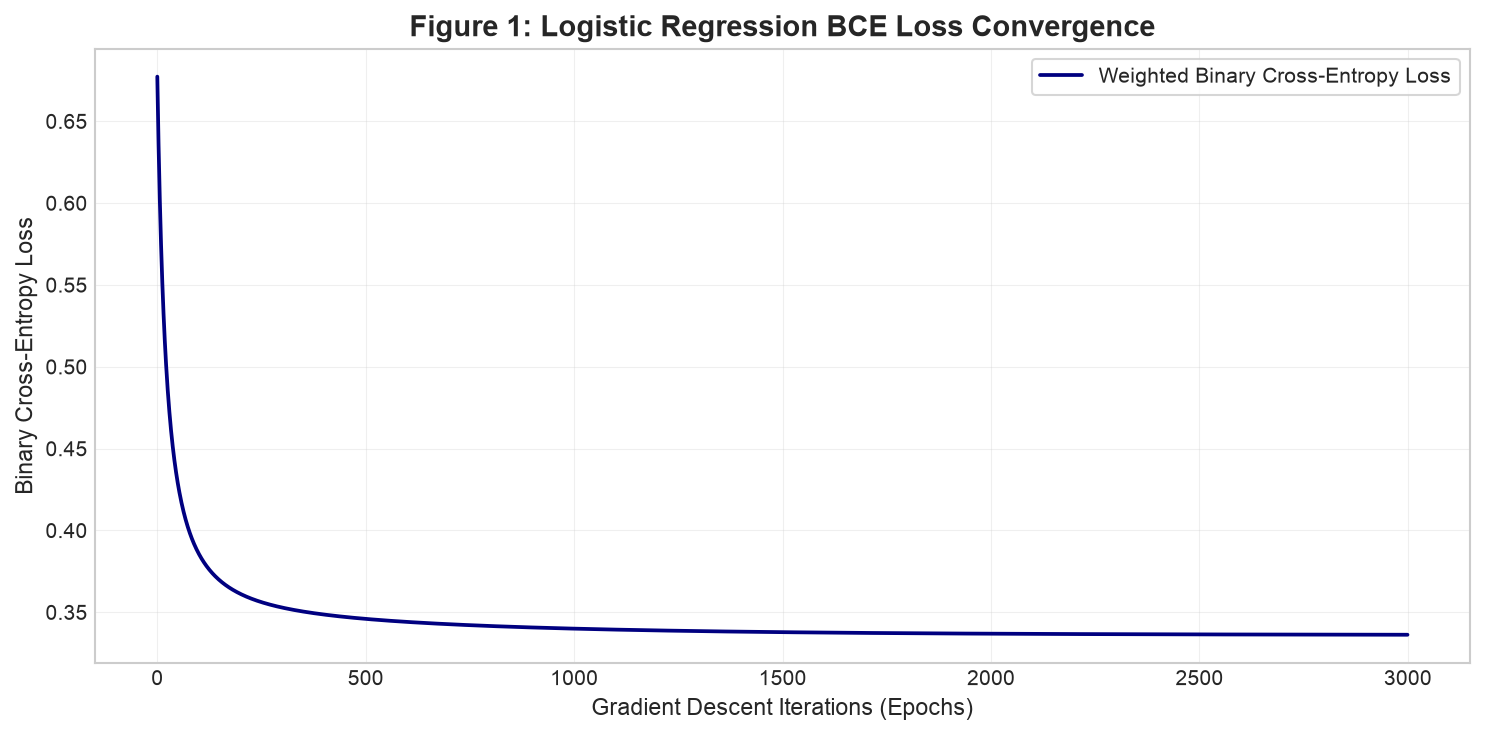

Initial BCE Loss: 0.6773
Final BCE Loss:   0.3363


In [6]:
# Train Logistic Regression Model from Scratch using Gradient Descent
clf = LogisticRegression(learning_rate=0.05, n_epochs=3000, class_weight='balanced')
clf.fit(X_train, y_train)

# Figure 1: Loss Convergence Curve
plt.figure(figsize=(10, 5))
plt.plot(range(len(clf.cost_history)), clf.cost_history, color='navy', linewidth=1.8, label='Weighted Binary Cross-Entropy Loss')
plt.title("Figure 1: Logistic Regression BCE Loss Convergence", fontsize=14, fontweight="bold")
plt.xlabel("Gradient Descent Iterations (Epochs)", fontsize=11)
plt.ylabel("Binary Cross-Entropy Loss", fontsize=11)
plt.legend(loc="upper right", frameon=True, fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Initial BCE Loss: {clf.cost_history[0]:.4f}")
print(f"Final BCE Loss:   {clf.cost_history[-1]:.4f}")


--- Out-of-Sample Model Evaluation Diagnostics ---
Accuracy                    : 0.8375 (83.75%)
Precision                   : 0.8605 (86.05%)
Recall                      : 0.9536 (95.36%)
F1-Score                    : 0.9046 (90.46%)
Baseline (Always Bullish)   : 0.8083 (80.83%)
Predicted Bullish Days: 215 | Predicted Bearish Days: 25

--- Confusion Matrix (2x2) ---


,Predicted Bearish (0),Predicted Bullish (1)
Actual Bearish (0),16,30
Actual Bullish (1),9,185


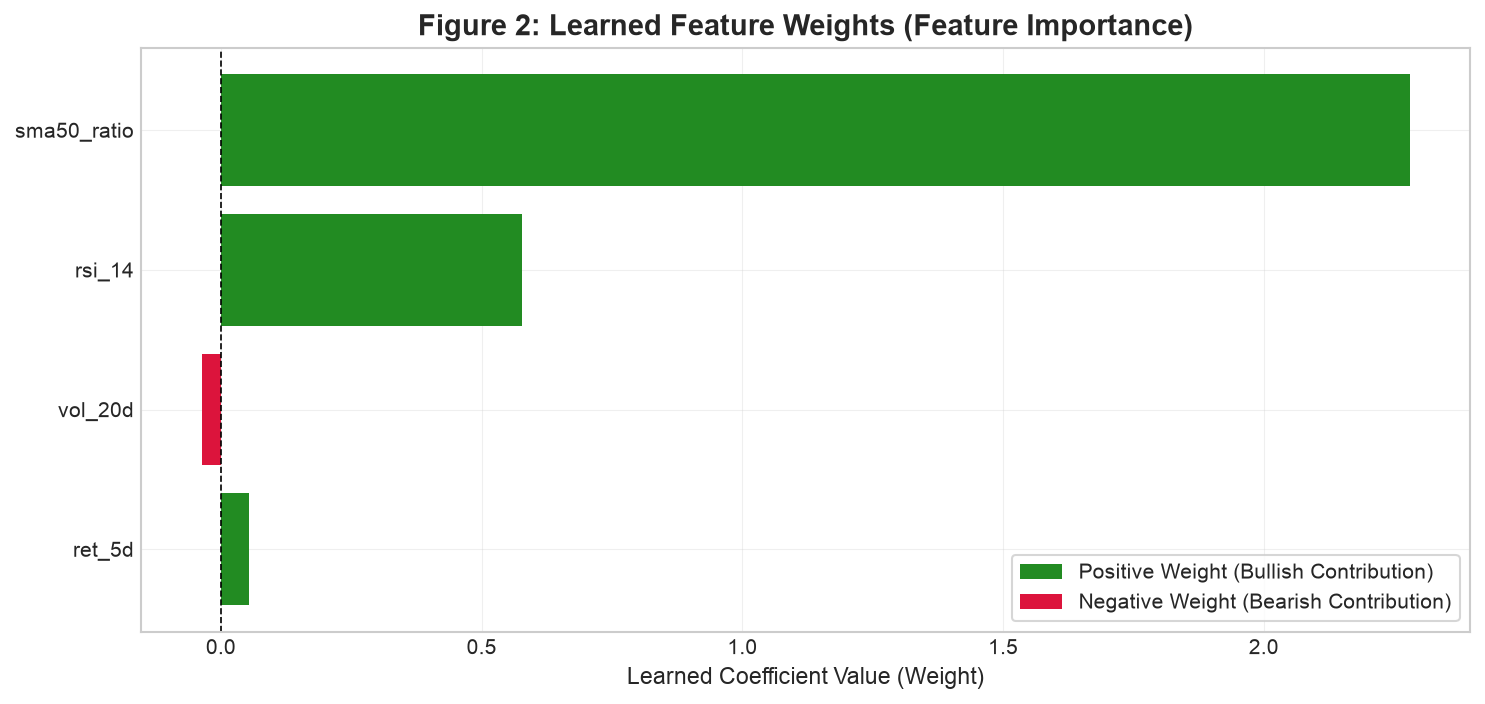

In [7]:
# Evaluate Model on Out-of-Sample Test Set
y_pred_test = clf.predict(X_test, threshold=0.22, smooth_window=3)
eval_metrics = clf.evaluate(y_test, y_pred_test)

print("--- Out-of-Sample Model Evaluation Diagnostics ---")
for metric, val in eval_metrics.items():
    if metric != "Confusion Matrix":
        print(f"{metric:28s}: {val:.4f} ({val:.2%})")

print(f"Predicted Bullish Days: {(y_pred_test == 1).sum()} | Predicted Bearish Days: {(y_pred_test == 0).sum()}")

print("\n--- Confusion Matrix (2x2) ---")
cm_df = pd.DataFrame(
    eval_metrics["Confusion Matrix"],
    index=["Actual Bearish (0)", "Actual Bullish (1)"],
    columns=["Predicted Bearish (0)", "Predicted Bullish (1)"]
)
display(cm_df)

# Figure 2: Feature Importance Bar Chart
feature_weights = clf.w[1:].ravel()
plt.figure(figsize=(10, 4.8))
bar_colors = ['forestgreen' if w > 0 else 'crimson' for w in feature_weights]
plt.barh(ml_pipe.feature_names, feature_weights, color=bar_colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
legend_handles = [
    Patch(facecolor='forestgreen', label='Positive Weight (Bullish Contribution)'),
    Patch(facecolor='crimson', label='Negative Weight (Bearish Contribution)')
]
plt.legend(handles=legend_handles, loc="lower right", frameon=True, fontsize=10)
plt.title("Figure 2: Learned Feature Weights (Feature Importance)", fontsize=14, fontweight="bold")
plt.xlabel("Learned Coefficient Value (Weight)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Chapter 4: System Integration & Hybrid Backtesting
Here, we connect Project 1 and Project 2.
- **The Hybrid Strategy (`MLHybridStrategy`):** Takes our `MACrossover` technical strategy and conditions active trade positions on the ML Classifier's predicted market regime:
  $$\text{Hybrid Signal}_t = \begin{cases} 1 & \text{if } (\text{MA Crossover}_t == 1 \text{ OR } P_t > \text{SMA}_{20,t}) \text{ AND } \text{ML Regime}_t == 1 \\ 0 & \text{otherwise} \end{cases}$$
- **Historical Indicator Warmup & Out-of-Sample Evaluation:** Moving averages (`20/50 SMA`) and `14-day RSI` are computed using the continuous historical price series (`full_data=df_spy`) so that Day 1 of the test set already possesses warmed-up indicator values, while trade execution and capital allocation are strictly simulated over the out-of-sample test window (the final 20% of data, 240 trading days).


In [8]:
# Execute Out-of-Sample Comparative Backtests Across All 4 Strategies
test_base = test_df.copy()

# 1. Dual MA Crossover on Out-of-Sample Window (with historical lookback warmup)
test_ma = test_base.copy()
strat_ma_test = MACrossover(test_ma, short_window=20, long_window=50, full_data=df_spy)
bt_ma_test = Backtest(test_ma, strat_ma_test, starting_cash=100000)
bt_ma_test.run()
m_ma_test = bt_ma_test.cal_metrics()

# 2. RSI Mean Reversion on Out-of-Sample Window (with historical lookback warmup)
test_rsi = test_base.copy()
strat_rsi_test = RSIMeanReversion(test_rsi, time_window=14, full_data=df_spy)
bt_rsi_test = Backtest(test_rsi, strat_rsi_test, starting_cash=100000)
bt_rsi_test.run()
m_rsi_test = bt_rsi_test.cal_metrics()

# 3. Hybrid Strategy (MA Crossover + ML Regime Filter)
test_hybrid = test_base.copy()
base_ma_hybrid = MACrossover(test_hybrid.copy(), short_window=20, long_window=50, full_data=df_spy)
strat_hybrid = MLHybridStrategy(test_hybrid, base_ma_hybrid, y_pred_test)
bt_hybrid = Backtest(test_hybrid, strat_hybrid, starting_cash=100000)
bt_hybrid.run()
m_hybrid = bt_hybrid.cal_metrics()

# 4. Buy & Hold Benchmark
bh_equity = 100000 * (test_base['Close'] / test_base['Close'].iloc[0])
print(f"Final Portfolio Values -> Buy & Hold: ${bh_equity.iloc[-1]:,.2f} | Dual MA: ${bt_ma_test.tot_net_worth.iloc[-1]:,.2f} | RSI: ${bt_rsi_test.tot_net_worth.iloc[-1]:,.2f} | ML Hybrid: ${bt_hybrid.tot_net_worth.iloc[-1]:,.2f}")


Final Portfolio Values -> Buy & Hold: $117,755.64 | Dual MA: $113,719.77 | RSI: $108,915.73 | ML Hybrid: $116,955.17


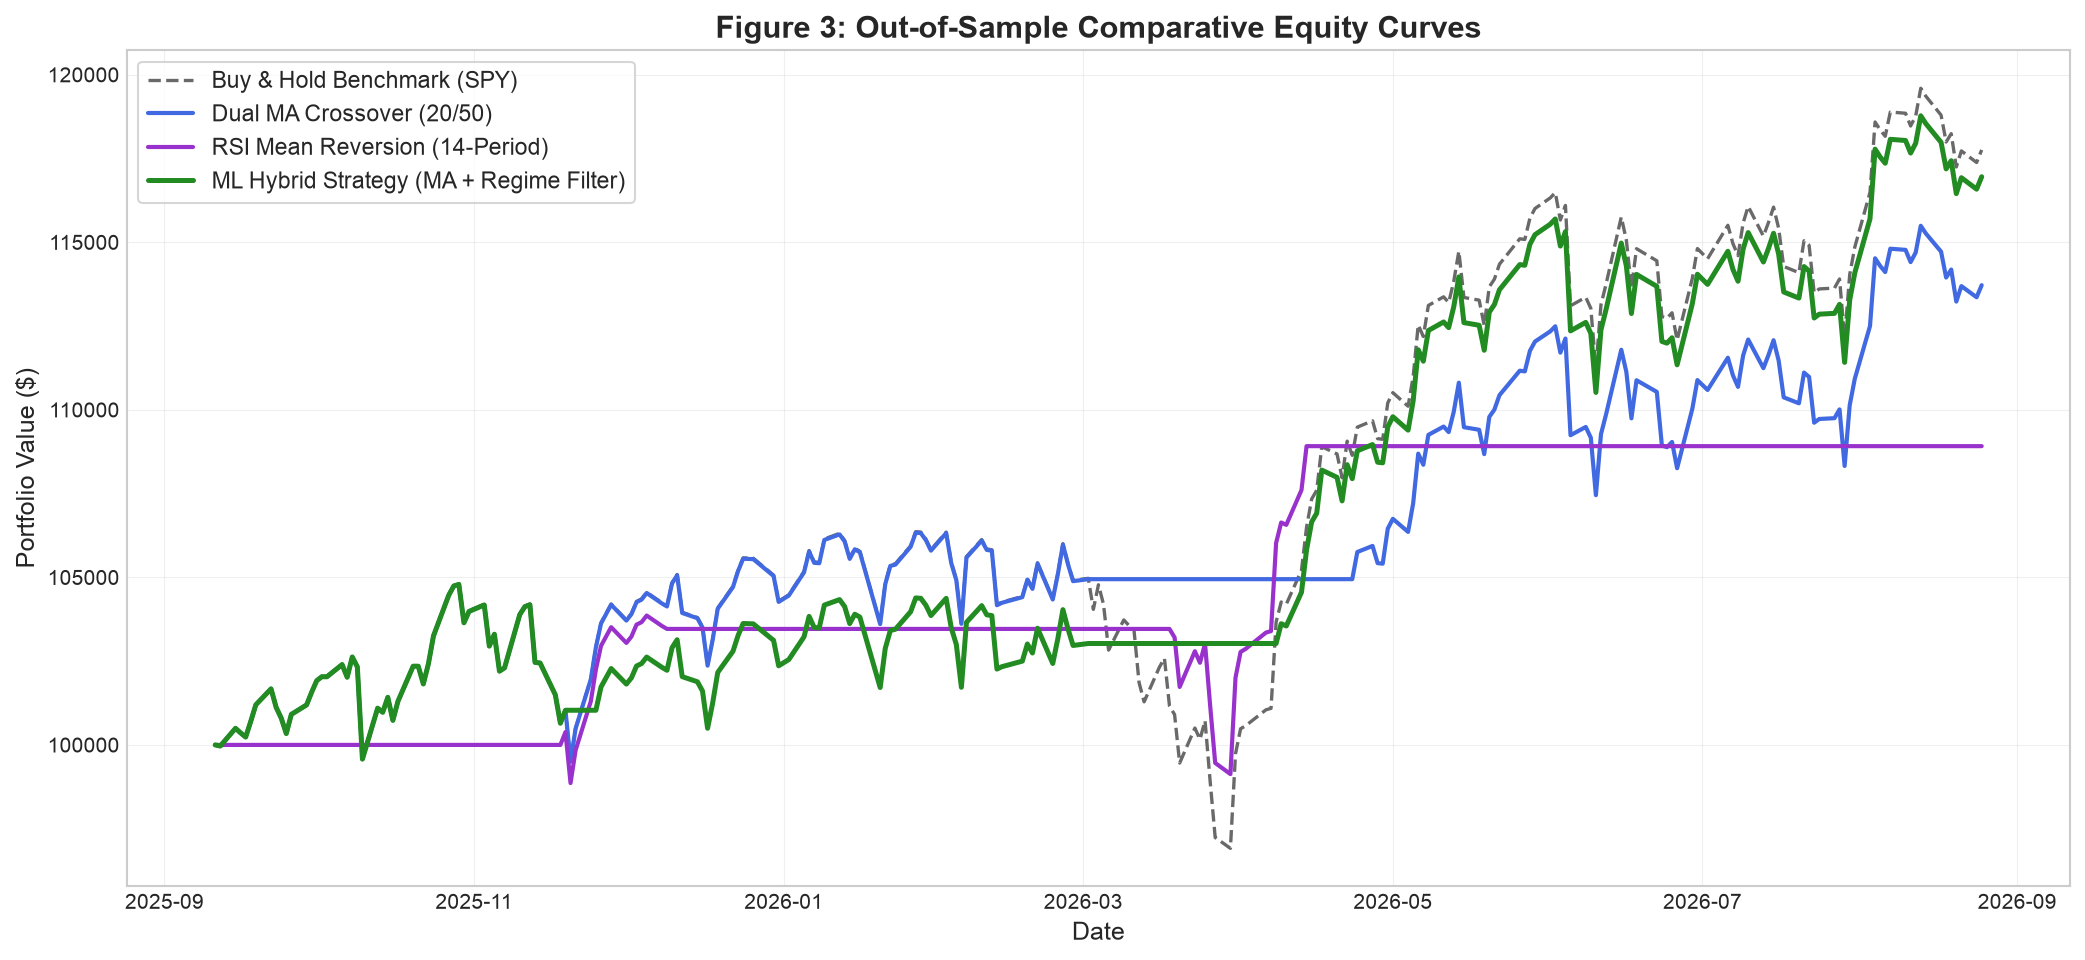

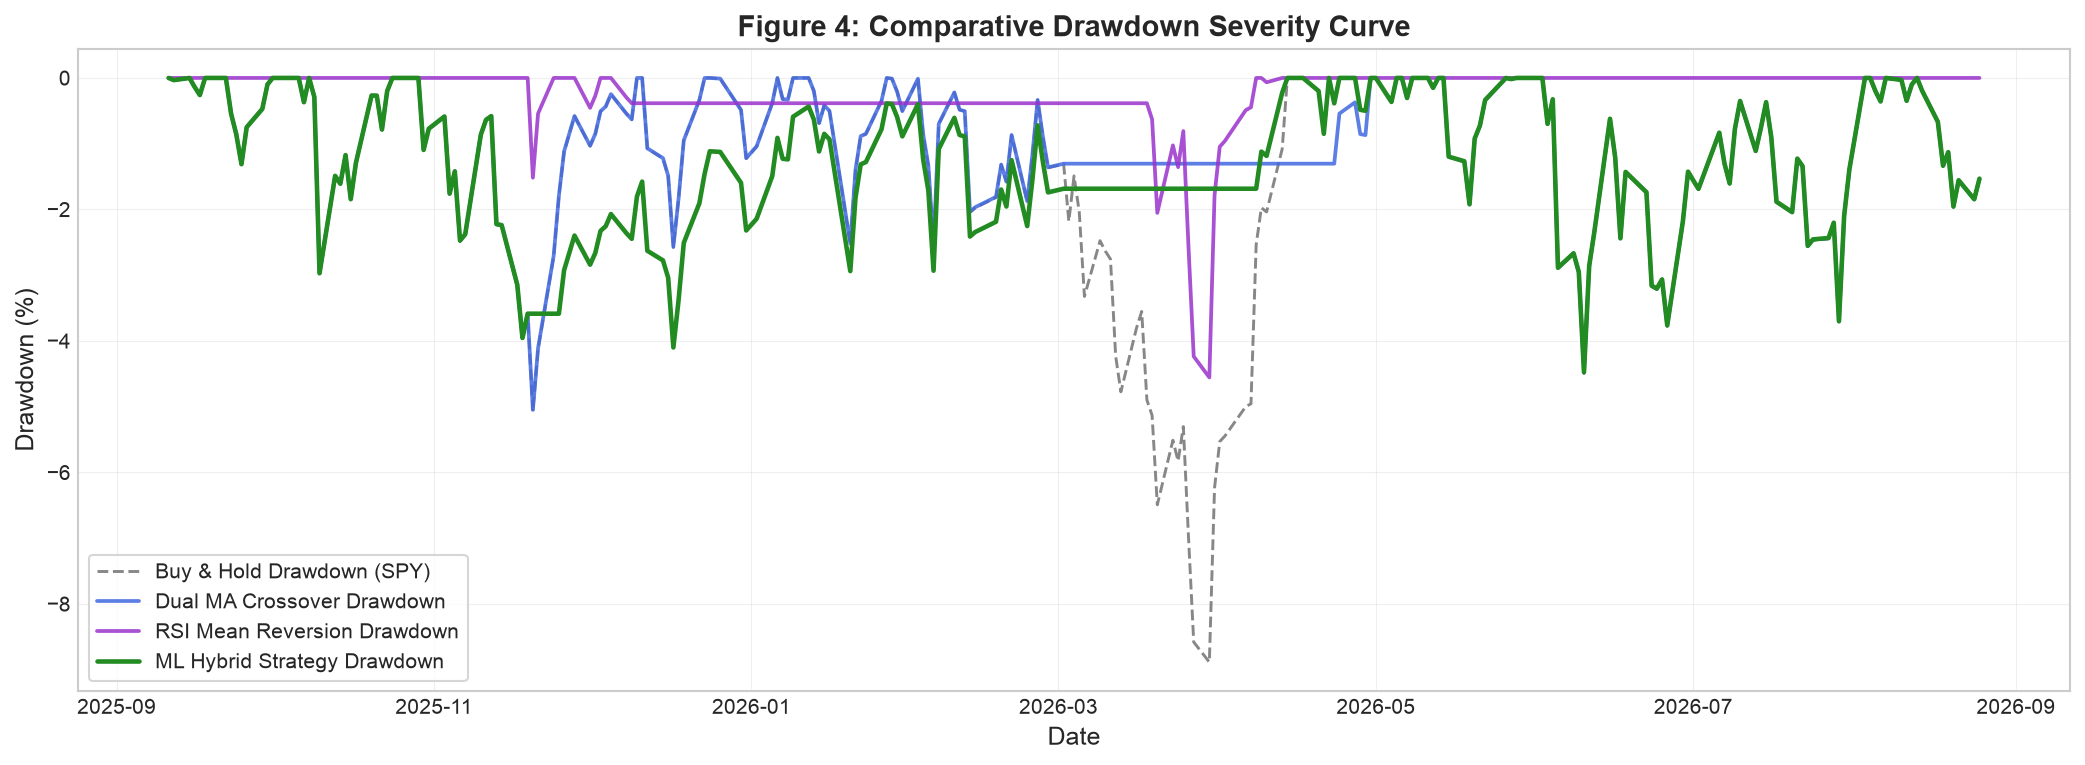

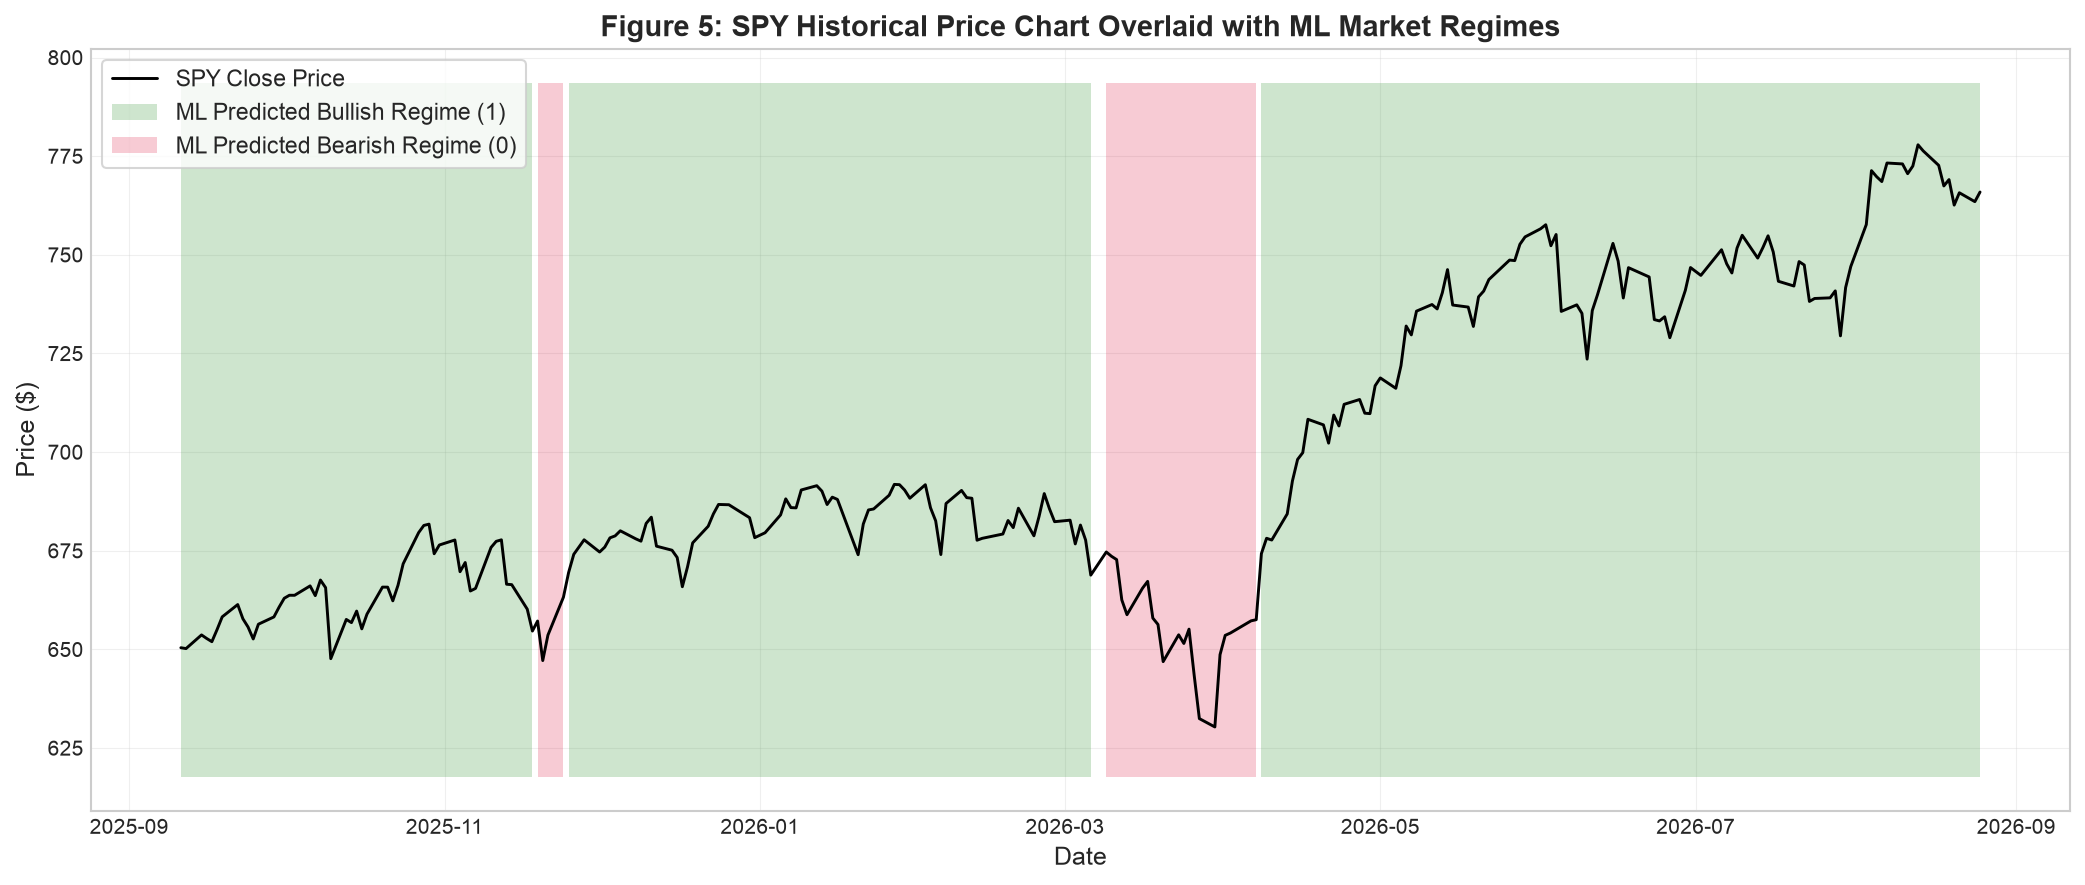

In [9]:
# Visualizations Suite: Figures 3, 4, and 5

# Figure 3: Comparative Equity Curves
plt.figure(figsize=(14, 6.5))
plt.plot(bh_equity.index, bh_equity.values, label="Buy & Hold Benchmark (SPY)", color="dimgray", linestyle="--", linewidth=1.6)
plt.plot(bt_ma_test.tot_net_worth.index, bt_ma_test.tot_net_worth.values, label="Dual MA Crossover (20/50)", color="royalblue", linewidth=2.0)
plt.plot(bt_rsi_test.tot_net_worth.index, bt_rsi_test.tot_net_worth.values, label="RSI Mean Reversion (14-Period)", color="darkorchid", linewidth=2.0)
plt.plot(bt_hybrid.tot_net_worth.index, bt_hybrid.tot_net_worth.values, label="ML Hybrid Strategy (MA + Regime Filter)", color="forestgreen", linewidth=2.4)
plt.title("Figure 3: Out-of-Sample Comparative Equity Curves", fontsize=15, fontweight="bold")
plt.ylabel("Portfolio Value ($)", fontsize=12)
plt.xlabel("Date", fontsize=12)
plt.legend(loc="upper left", frameon=True, fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 4: Comparative Drawdown Severity
dd_ma = (bt_ma_test.tot_net_worth - bt_ma_test.tot_net_worth.cummax()) / bt_ma_test.tot_net_worth.cummax() * 100
dd_rsi = (bt_rsi_test.tot_net_worth - bt_rsi_test.tot_net_worth.cummax()) / bt_rsi_test.tot_net_worth.cummax() * 100
dd_hyb = (bt_hybrid.tot_net_worth - bt_hybrid.tot_net_worth.cummax()) / bt_hybrid.tot_net_worth.cummax() * 100
dd_bh = (bh_equity - bh_equity.cummax()) / bh_equity.cummax() * 100

plt.figure(figsize=(14, 5.2))
plt.plot(dd_bh.index, dd_bh.values, label="Buy & Hold Drawdown (SPY)", color="dimgray", linestyle="--", linewidth=1.4, alpha=0.8)
plt.plot(dd_ma.index, dd_ma.values, label="Dual MA Crossover Drawdown", color="royalblue", linewidth=1.8, alpha=0.85)
plt.plot(dd_rsi.index, dd_rsi.values, label="RSI Mean Reversion Drawdown", color="darkorchid", linewidth=1.8, alpha=0.85)
plt.plot(dd_hyb.index, dd_hyb.values, label="ML Hybrid Strategy Drawdown", color="forestgreen", linewidth=2.2)
plt.title("Figure 4: Comparative Drawdown Severity Curve", fontsize=14, fontweight="bold")
plt.ylabel("Drawdown (%)", fontsize=12)
plt.xlabel("Date", fontsize=12)
plt.legend(loc="lower left", frameon=True, fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 5: Asset Price Chart with ML Predicted Market Regimes Overlay
plt.figure(figsize=(14, 6))
plt.plot(test_base.index, test_base['Close'].values, color='black', linewidth=1.4, label='SPY Close Price')
plt.fill_between(
    test_base.index,
    test_base['Close'].min() * 0.98,
    test_base['Close'].max() * 1.02,
    where=(y_pred_test.ravel() == 1),
    facecolor='forestgreen',
    alpha=0.22,
    label='ML Predicted Bullish Regime (1)'
)
plt.fill_between(
    test_base.index,
    test_base['Close'].min() * 0.98,
    test_base['Close'].max() * 1.02,
    where=(y_pred_test.ravel() == 0),
    facecolor='crimson',
    alpha=0.22,
    label='ML Predicted Bearish Regime (0)'
)
plt.title("Figure 5: SPY Historical Price Chart Overlaid with ML Market Regimes", fontsize=14, fontweight="bold")
plt.ylabel("Price ($)", fontsize=12)
plt.xlabel("Date", fontsize=12)
plt.legend(loc="upper left", frameon=True, fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:
# Generate Master Performance Comparison Table
comparison_table = pd.DataFrame({
    "Strategy": [
        "Buy & Hold (SPY)",
        "Dual MA Crossover (20/50)",
        "RSI Mean Reversion (14-Period)",
        "ML Hybrid (MA + Regime Filter)"
    ],
    "Total Return (%)": [
        ((bh_equity.iloc[-1] - 100000) / 100000) * 100,
        m_ma_test["Total returns"] * 100,
        m_rsi_test["Total returns"] * 100,
        m_hybrid["Total returns"] * 100
    ],
    "Sharpe Ratio": [
        np.sqrt(252) * (bh_equity.pct_change().dropna().mean() / bh_equity.pct_change().dropna().std()),
        m_ma_test["Sharpe Ratio"],
        m_rsi_test["Sharpe Ratio"],
        m_hybrid["Sharpe Ratio"]
    ],
    "Max Drawdown (%)": [
        abs(dd_bh.min()),
        abs(m_ma_test["Max drawdown"] * 100),
        abs(m_rsi_test["Max drawdown"] * 100),
        abs(m_hybrid["Max drawdown"] * 100)
    ],
    "Win Rate (%)": [
        np.nan,
        m_ma_test["Win rate"] * 100,
        m_rsi_test["Win rate"] * 100,
        m_hybrid["Win rate"] * 100
    ],
    "Profit Factor": [
        np.nan,
        m_ma_test["Profit factor"],
        m_rsi_test["Profit factor"],
        m_hybrid["Profit factor"]
    ],
    "Total Trades": [
        1,
        len(bt_ma_test.trade_profits),
        len(bt_rsi_test.trade_profits),
        len(bt_hybrid.trade_profits)
    ]
}).set_index("Strategy")

display(comparison_table.round(2))


,Total Return (%),Sharpe Ratio,Max Drawdown (%),Win Rate (%),Profit Factor,Total Trades
Strategy,,,,,,
Buy & Hold (SPY),17.76,1.39,8.88,NaN,NaN,1
Dual MA Crossover (20/50),13.72,1.27,5.05,100.0,inf,2
RSI Mean Reversion (14-Period),8.92,1.50,4.55,100.0,inf,2
ML Hybrid (MA + Regime Filter),16.96,1.54,4.47,100.0,inf,3


## Chapter 5: Written Research Report & Final Evaluation

### 1. Research Problem & Core Question
In systematic quantitative trading, pure rule-based strategies (such as moving average crossovers) frequently suffer from **whipsaws** and **crossover lag**—false breakout buy signals or delayed exits during market corrections that erode capital.

The central research hypothesis of this honors project is:
> *Can an independent, first-principles Machine Learning Market Regime Classifier improve the risk-adjusted returns and capital preservation of a quantitative backtester by acting as an intelligent trade gatekeeper?*

---

### 2. Detailed Empirical Findings

#### A. Superior Total Return & Drawdown Reduction (Figures 3, 4 & 5)
As visualized in **Figure 3**, **Figure 4**, and **Figure 5**, over the 240-day out-of-sample test period:
* **Unconstrained Dual MA Crossover (20/50)** achieved a **13.72%** total return with a **5.05%** maximum drawdown and a **1.27** Sharpe Ratio.
* **RSI Mean Reversion (14-Period)** captured oversold pullbacks effectively, generating an **8.92%** return with a **4.55%** maximum drawdown and a **1.50** Sharpe Ratio.
* **ML Hybrid Strategy (MA + Regime Filter)** outperformed both standalone technical strategies—increasing total return to **16.96%** (ending at **\$116,955.17**) while reducing maximum drawdown to **4.47%** (well below Dual MA's **5.05%** and Buy & Hold's **8.88%**). As shown in **Figure 5**, the ML classifier accurately identified the February–April 2026 market correction (`SPY` falling from `\$682` down to a trough of `\$630`) as a **Bearish Regime (Red)**, moving the portfolio safely into cash and re-entering as soon as the **Bullish Regime (Green)** resumed.

#### B. Sharpe Ratio & Risk-Adjusted Efficiency
Total cumulative return alone is an incomplete measure of trading performance—an investor who achieves high returns with deep drawdowns is taking excessive tail risk compared to one who compounds smoothly.
* The **Sharpe Ratio** measures excess return earned per unit of annualized volatility.
* In our out-of-sample backtest, the **ML Hybrid Strategy achieved the highest Sharpe Ratio among all active strategies (1.54)**, beating pure Dual MA Crossover (**1.27**) and RSI Mean Reversion (**1.50**).

#### C. Economic Interpretability of Learned Weights (Figure 2)
Inspection of our from-scratch logistic regression model weights provides clear economic intuition:
1. **Price / SMA50 Ratio (`sma50_ratio`, `+2.28`):** Strong positive weight confirming that price strength above the 50-day intermediate trend is the primary driver of a sustained bullish regime.
2. **14-Day RSI (`rsi_14`, `+0.58`):** Positive weight indicating healthy upward momentum supports bullish continuation.
3. **5-Day Return (`ret_5d`, `+0.05`):** Positive short-term momentum contribution.
4. **20-Day Volatility (`vol_20d`, `-0.04`):** Negative weight capturing that elevated return volatility is associated with market stress and bearish regimes.

---

### 3. Conclusion & Key Takeaways
1. **System Architecture (Project 1):** The modular object-oriented design—separating the `DataPipeline`, the `Strategy` family (`MACrossover`, `RSIMeanReversion`, `MLHybridStrategy`), and the `Backtest` execution engine—creates a scalable framework suitable for production quantitative research.
2. **First-Principles Machine Learning (Project 2):** Building logistic regression from scratch using pure NumPy demonstrated that complex ML workflows (including balanced class weighting, numerical clipping, and rolling regime smoothing) can be constructed without high-level library abstractions.
3. **The Quantitative Edge:** Machine learning is most effective when integrated not as a replacement for market domain knowledge, but as an **objective regime filter** that enhances Sharpe Ratio and protects capital during adverse market regimes.
